In [ ]:
%pip install h5netcdf

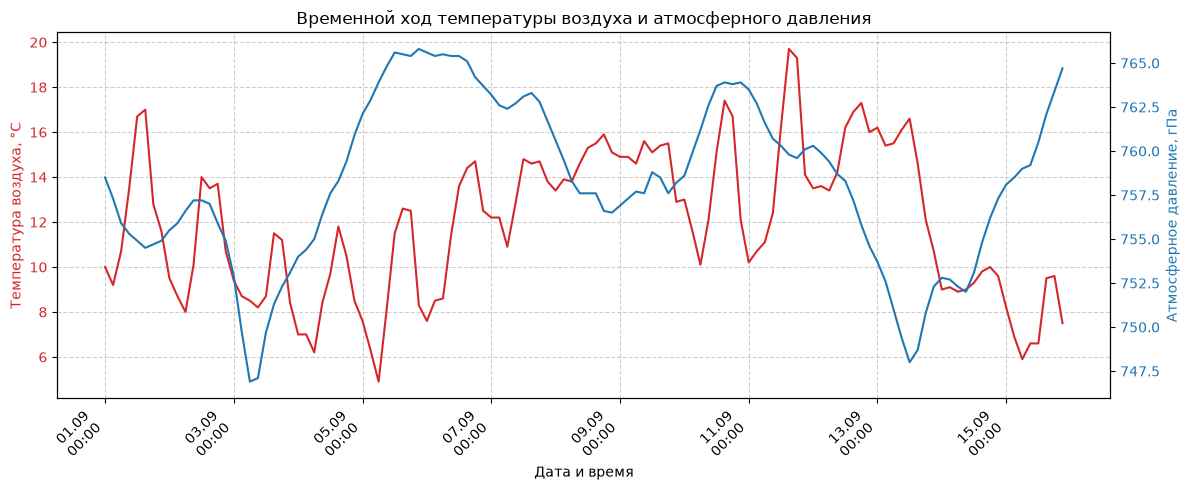

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df = pd.read_excel('September.xlsx', sheet_name='Лист1')
df['Time'] = pd.to_datetime(df['Time'])
df = df.sort_values('Time')

fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.set_xlabel('Дата и время')
ax1.set_ylabel('Температура воздуха, °C', color='tab:red')
ax1.plot(df['Time'], df['Temperature'], color='tab:red')
ax1.tick_params(axis='y', labelcolor='tab:red')
ax1.grid(True, linestyle='--', alpha=0.6)

ax1.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m\n%H:%M'))
plt.setp(ax1.get_xticklabels(), rotation=45, ha='right')

ax2 = ax1.twinx()
ax2.set_ylabel('Атмосферное давление, гПа', color='tab:blue')
ax2.plot(df['Time'], df['Pressure'], color='tab:blue')
ax2.tick_params(axis='y', labelcolor='tab:blue')

plt.title('Временной ход температуры воздуха и атмосферного давления')
fig.tight_layout()
plt.savefig('Временной ход температуры воздуха и атмосферного давления.png', dpi=300, bbox_inches='tight')
plt.show()


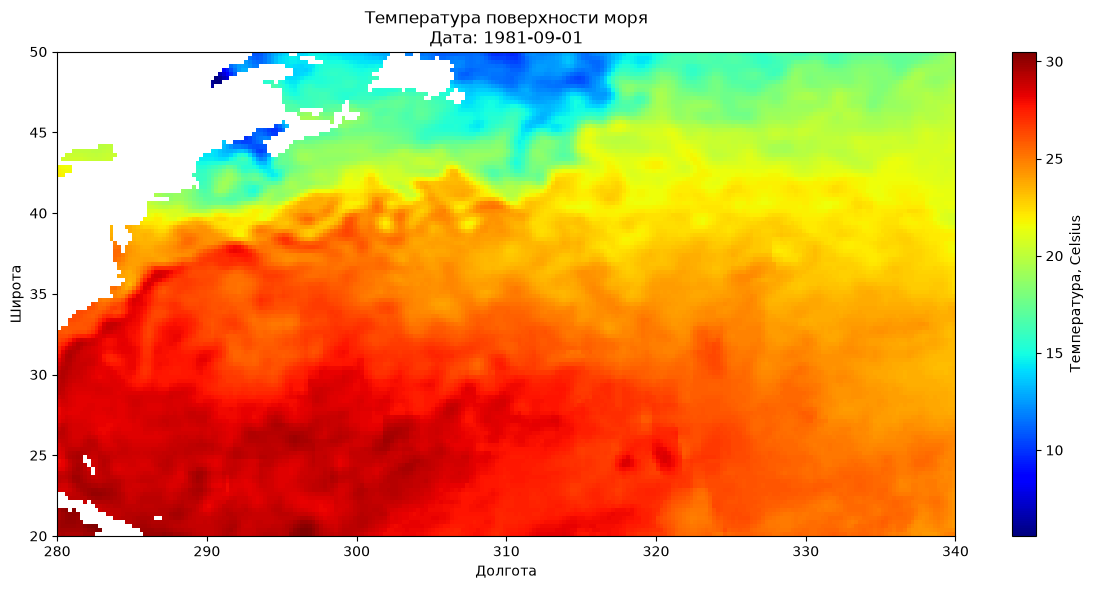

In [3]:
import xarray as xr
import matplotlib.pyplot as plt


ds = xr.open_dataset('sst.nc', engine='h5netcdf')
sst_name = 'sst'

if ds[sst_name].attrs.get('units') == 'K':
    ds[sst_name] = ds[sst_name] - 273.15
    ds[sst_name].attrs['units'] = '°C'

if 'time' in ds[sst_name].dims:
    sst_slice = ds[sst_name].isel(time=0)
    date_str = str(ds['time'].isel(time=0).values)[:10]
else:
    sst_slice = ds[sst_name]
    date_str = ""

region = sst_slice.sel(lat=slice(20, 50), lon=slice(280, 340))

plt.figure(figsize=(12, 6))
region.plot(
    cmap='jet',
    cbar_kwargs={'label': f'Температура, {ds[sst_name].attrs.get("units", "°C")}'}
)
plt.title(f'Температура поверхности моря\nДата: {date_str}')
plt.xlabel('Долгота')
plt.ylabel('Широта')
plt.tight_layout()
plt.savefig('Температура поверхности моря.png', dpi=300, bbox_inches='tight')
plt.show()